In [1]:
import numpy as np
import pandas as pd
import math
from pandas.plotting import scatter_matrix
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
import os
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import glob
from scipy.spatial import ConvexHull, Delaunay, cKDTree

CHARGING DATA

In [2]:
# Path to files
measured_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/measured'
param_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/lhs_26_params'
seeds = [0]

# Load files
measured_file_names = glob.glob(f"{measured_files_path}/id*.txt")
measured_file_names = sorted([f for f in measured_file_names if any(f"seed{seed}_" in f for seed in seeds)])
param_file_names = glob.glob(f"{param_files_path}/param_id*.npy")
param_file_names = sorted([f for f in param_file_names if any(f"seed{seed}_" in f for seed in seeds)])

measured_files_txt = [np.loadtxt(file) for file in measured_file_names]
param_files = [np.load(file) for file in param_file_names]

# Create list of measured files, column 4 "xi"
measured_files = []
for i in range(len(measured_files_txt)):
    data = measured_files_txt[i]
    row = [row[3] for row in data]
    measured_files.append(row)

measured_files = np.array(measured_files)
print("Seeds : ",seeds)
print("Shape param_files : ", np.shape(param_files))
print("Shape measured_files : ",np.shape(measured_files))


Seeds :  [0]
Shape param_files :  (2704, 4)
Shape measured_files :  (2704, 10)


PCA theory ddb26 + 26 + 1000

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import os
import matplotlib.pyplot as plt
import glob
from scipy.spatial import ConvexHull

In [ ]:
# Path to files
dbb26_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/theory_2pcf'
cosmoslics_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_COSMOSLICS/theory_2pcf'
dbb1000_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_1000/theory_2pcf'

# Load files
dbb26_files_names = sorted(glob.glob(f"{dbb26_files_path}/id*2pcf.dat"))
dbb26_files_full = [np.loadtxt(file) for file in dbb26_files_names]
cosmoslics_files_names = sorted(glob.glob(f"{cosmoslics_files_path}/id*2pcf.dat"))
cosmoslics_files_full = [np.loadtxt(file) for file in cosmoslics_files_names]
dbb1000_files_names = sorted(glob.glob(f"{dbb1000_files_path}/id*2pcf.dat"))
dbb1000_files_full = [np.loadtxt(file) for file in dbb1000_files_names]

# Create list of measured files
dbb26_files = []
for i in range(len(dbb26_files_full)):
    data = dbb26_files_full[i]
    row = [row[1] for row in data]
    dbb26_files.append(row)

cosmoslics_files = []
for i in range(len(cosmoslics_files_full)):
    data = cosmoslics_files_full[i]
    row = [row[1] for row in data]
    cosmoslics_files.append(row)

dbb1000_files = []
for i in range(len(dbb1000_files_full)):
    data = dbb1000_files_full[i]
    row = [row[1] for row in data]
    dbb1000_files.append(row)


print("Shape dbb26 : ",np.shape(dbb26_files))
print("Shape cosmoslics : ",np.shape(cosmoslics_files))
print("Shape dbb1000 : ",np.shape(dbb1000_files))

In [ ]:
full_files = np.concatenate([dbb26_files,cosmoslics_files,dbb1000_files])

# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(dbb26_files) + [1]*len(cosmoslics_files) + [2]*len(dbb1000_files))

In [ ]:
# Standardisation
scaler = StandardScaler()
scaled_full = scaler.fit_transform(full_files)

# PCA
pca_full = PCA(n_components=4)
principal_components_full = pca_full.fit_transform(scaled_full)

In [ ]:
# Explained variance
explained_variance_full = pca_full.explained_variance_ratio_

# Plot explained variance ratio
plt.figure(figsize=(10, 7))
plt.bar(range(0, pca_full.n_components_), pca_full.explained_variance_ratio_, alpha=0.5, align='center')
plt.plot(np.cumsum(explained_variance_full), marker='o')
plt.ylabel('Variance proportion')
plt.xlabel('Principal components')
plt.title('Variance explained by each component')
plt.grid()
plt.show()

In [ ]:
# PCA
pca_full = PCA(n_components=2)
principal_components_full = pca_full.fit_transform(scaled_full)

# MASKS
# Create masks for the two groups
mask_dbb26 = labels == 0
mask_cosmo = labels == 1
mask_dbb1000 = labels == 2

# Plot the first two principal components
plt.figure(figsize=(10, 6))
plt.scatter(principal_components_full[mask_dbb26, 0], principal_components_full[mask_dbb26, 1],s=20,color='blue',label='lhs_26')
plt.scatter(principal_components_full[mask_cosmo, 0], principal_components_full[mask_cosmo, 1],s=20,color='red',label='cosmo-SLICS')
plt.scatter(principal_components_full[mask_dbb1000, 0], principal_components_full[mask_dbb1000, 1],s=10,alpha=0.3,color='green',label='lhs_1000')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('First Two Principal Components')

convexhull=1
if convexhull :
    # Calculate and plot the convex hull for the blue points
    cosmo_points = principal_components_full[mask_cosmo]
    hull = ConvexHull(cosmo_points)
    for simplex in hull.simplices:
        plt.plot(cosmo_points[simplex, 0], cosmo_points[simplex, 1], color='red')

    dbb26_points = principal_components_full[mask_dbb26]
    hull26 = ConvexHull(dbb26_points)
    for simplex in hull26.simplices:
        plt.plot(dbb26_points[simplex, 0], dbb26_points[simplex, 1], color='blue')

plt.legend()
plt.grid()
plt.show()

PCA THEORY, LHS26 LHS1000 COSMOSLICS MAXIMIN

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import os
import matplotlib.pyplot as plt
import glob
from scipy.spatial import ConvexHull, Delaunay

In [ ]:
# Path to files
dbb26_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/theory_2pcf'
dbb26maximin_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26maximin/theory_2pcf'
dbb26maximin2_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26maximin/theory_2pcf_2'
cosmoslics_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_COSMOSLICS/theory_2pcf'
dbb1000_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_1000/theory_2pcf'


# Load files
dbb26_files_names = sorted(glob.glob(f"{dbb26_files_path}/id*2pcf.dat"))
dbb26_files_full = [np.loadtxt(file) for file in dbb26_files_names]
dbb26maximin_files_names = sorted(glob.glob(f"{dbb26maximin_files_path}/id*2pcf.dat"))
dbb26maximin_files_full = [np.loadtxt(file) for file in dbb26maximin_files_names]
dbb26maximin2_files_names = sorted(glob.glob(f"{dbb26maximin2_files_path}/id*2pcf.dat"))
dbb26maximin2_files_full = [np.loadtxt(file) for file in dbb26maximin2_files_names]
cosmoslics_files_names = sorted(glob.glob(f"{cosmoslics_files_path}/id*2pcf.dat"))
cosmoslics_files_full = [np.loadtxt(file) for file in cosmoslics_files_names]
dbb1000_files_names = sorted(glob.glob(f"{dbb1000_files_path}/id*2pcf.dat"))
dbb1000_files_full = [np.loadtxt(file) for file in dbb1000_files_names]


# Create list of measured files
dbb26_files = []
for i in range(len(dbb26_files_full)):
   data = dbb26_files_full[i]
   row = [row[1] for row in data]
   dbb26_files.append(row)

dbb26maximin_files = []
for i in range(len(dbb26maximin_files_full)):
   data = dbb26maximin_files_full[i]
   row = [row[1] for row in data]
   dbb26maximin_files.append(row)

dbb26maximin2_files = []
for i in range(len(dbb26maximin2_files_full)):
   data = dbb26maximin2_files_full[i]
   row = [row[1] for row in data]
   dbb26maximin2_files.append(row)


cosmoslics_files = []
for i in range(len(cosmoslics_files_full)):
   data = cosmoslics_files_full[i]
   row = [row[1] for row in data]
   cosmoslics_files.append(row)


dbb1000_files = []
for i in range(len(dbb1000_files_full)):
   data = dbb1000_files_full[i]
   row = [row[1] for row in data]
   dbb1000_files.append(row)


print("Shape dbb26 : ",np.shape(dbb26_files))
print("Shape dbb26maximin : ",np.shape(dbb26maximin_files))
print("Shape dbb26maximin2 : ",np.shape(dbb26maximin2_files))
print("Shape cosmoslics : ",np.shape(cosmoslics_files))
print("Shape dbb1000 : ",np.shape(dbb1000_files))

In [ ]:
full_maximin = np.concatenate([dbb26_files,cosmoslics_files,dbb1000_files, dbb26maximin_files,dbb26maximin2_files])


# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(dbb26_files) + [1]*len(cosmoslics_files) + [2]*len(dbb1000_files) + [3]*len(dbb26maximin_files) +[4]*len(dbb26maximin2_files) )

In [ ]:
# Standardisation
scaler = StandardScaler()
scaled_max = scaler.fit_transform(full_maximin)


# PCA
pca_maximin = PCA(n_components=4)
principal_components_maximin = pca_maximin.fit_transform(scaled_max)

In [ ]:
# Explained variance
explained_variance_maximin = pca_maximin.explained_variance_ratio_


# Plot explained variance ratio
plt.figure(figsize=(10, 7))
plt.bar(range(0, pca_maximin.n_components_), pca_maximin.explained_variance_ratio_, alpha=0.5, align='center')
plt.plot(np.cumsum(explained_variance_maximin), marker='o')
plt.ylabel('Variance proportion')
plt.xlabel('Principal components')
plt.title('Variance explained by each component')
plt.grid()
plt.show()


In [ ]:
# PCA
pca_maximin = PCA(n_components=2)
principal_components_maximin = pca_maximin.fit_transform(scaled_max)


# MASKS
# Create masks for the two groups
mask_dbb26 = labels == 0
mask_cosmo = labels == 1
mask_dbb1000 = labels == 2
mask_dbb26maximin = labels == 3
mask_dbb26maximin2 = labels == 4


# Plot the first two principal components
plt.figure(figsize=(10, 6))
plt.scatter(principal_components_maximin[mask_dbb26, 0], principal_components_maximin[mask_dbb26, 1],s=20,color='blue',label='lhs_26')
plt.scatter(principal_components_maximin[mask_cosmo, 0], principal_components_maximin[mask_cosmo, 1],s=20,color='red',label='cosmo-SLICS')
plt.scatter(principal_components_maximin[mask_dbb26maximin, 0], principal_components_maximin[mask_dbb26maximin, 1],s=20,color='orange',label='Maximin_26')
plt.scatter(principal_components_maximin[mask_dbb26maximin2, 0], principal_components_maximin[mask_dbb26maximin2, 1],s=20,color='purple',label='Maximin_26_2')
plt.scatter(principal_components_maximin[mask_dbb1000, 0], principal_components_maximin[mask_dbb1000, 1],s=10,alpha=0.3,color='green',label='lhs_1000')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('First Two Principal Components')


convexhull=1
if convexhull :
    # Calculate and plot the convex hull for the blue points
    cosmo_points = principal_components_maximin[mask_cosmo]
    hull = ConvexHull(cosmo_points)
    for simplex in hull.simplices:
        plt.plot(cosmo_points[simplex, 0], cosmo_points[simplex, 1], color='red')

    dbb26_points = principal_components_maximin[mask_dbb26]
    hull26 = ConvexHull(dbb26_points)
    for simplex in hull26.simplices:
        plt.plot(dbb26_points[simplex, 0], dbb26_points[simplex, 1], color='blue')

    max26_points = principal_components_maximin[mask_dbb26maximin]
    hull26max = ConvexHull(max26_points)
    for simplex in hull26max.simplices:
        plt.plot(max26_points[simplex, 0], max26_points[simplex, 1], color='orange')
    
    max26_points2 = principal_components_maximin[mask_dbb26maximin2]
    hull26max2 = ConvexHull(max26_points2)
    for simplex in hull26max2.simplices:
        plt.plot(max26_points2[simplex, 0], max26_points2[simplex, 1], color='purple')

    dbb1000_points = principal_components_maximin[mask_dbb1000]
    hull1000 = ConvexHull(dbb1000_points)
    for simplex in hull1000.simplices:
        plt.plot(dbb1000_points[simplex, 0], dbb1000_points[simplex, 1], color='green')


    # Use Delaunay to check if points are inside the convex hull
    delaunay_26 = Delaunay(dbb26_points)
    delaunay_cosmo = Delaunay(cosmo_points)
    delaunay_26max = Delaunay(max26_points)
    inside_26 = delaunay_26.find_simplex(dbb1000_points) >= 0
    inside_cosmo = delaunay_cosmo.find_simplex(dbb1000_points) >= 0
    inside_26max = delaunay_26max.find_simplex(dbb1000_points) >= 0
    
    # Count points inside the convex hull
    count_26 = np.sum(inside_26)
    count_cosmo = np.sum(inside_cosmo)
    count_26max = np.sum(inside_26max)
    
    print(f"Number of LHS26 inside LHS1000 convex hull: {count_26}")
    print(f"Number of cosmoslics inside LHS1000 convex hull: {count_cosmo}")
    print(f"Number of Maximin26 inside LHS1000 convex hull: {count_26max}")

plt.legend()
plt.grid()
plt.show()

Comparison Maximin and normal LHS for 1000 cosmologies



In [77]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import os
import matplotlib.pyplot as plt
import glob
from scipy.spatial import ConvexHull, Delaunay

In [78]:
# Path to files
dbb1000_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_1000/theory_2pcf'
max1000_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_1000/theory_2pcf_maximin'


# Load files
dbb1000_files_names = sorted(glob.glob(f"{dbb1000_files_path}/id*2pcf.dat"))
dbb1000_files_full = [np.loadtxt(file) for file in dbb1000_files_names]
max1000_files_names = sorted(glob.glob(f"{max1000_files_path}/id*2pcf.dat"))
max1000_files_full = [np.loadtxt(file) for file in max1000_files_names]


# Create list of measured files
dbb1000_files = []
#for i in range(len(dbb1000_files_full)):
for i in range(700):
   data = dbb1000_files_full[i]
   row = [row[1] for row in data]
   dbb1000_files.append(row)

max1000_files = []
for i in range(len(max1000_files_full)):
   data = max1000_files_full[i]
   row = [row[1] for row in data]
   max1000_files.append(row)

print("Shape dbb1000 : ",np.shape(dbb1000_files))
print("Shape max1000 : ",np.shape(max1000_files))

Shape dbb1000 :  (700, 10)
Shape max1000 :  (700, 10)


In [79]:
full_1000 = np.concatenate([dbb1000_files, max1000_files])


# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(dbb1000_files) + [1]*len(max1000_files))

In [80]:
# Standardisation
scaler = StandardScaler()
scaled_max1000 = scaler.fit_transform(full_1000)


# PCA
pca_1000 = PCA(n_components=4)
principal_components_maximin = pca_1000.fit_transform(scaled_max1000)

In [ ]:
# Explained variance
explained_variance_1000 = pca_1000.explained_variance_ratio_


# Plot explained variance ratio
plt.figure(figsize=(10, 7))
plt.bar(range(0, pca_1000.n_components_), pca_1000.explained_variance_ratio_, alpha=0.5, align='center')
plt.plot(np.cumsum(explained_variance_1000), marker='o')
plt.ylabel('Variance proportion')
plt.xlabel('Principal components')
plt.title('Variance explained by each component')
plt.grid()
plt.show()

In [ ]:
# PCA
pca_1000 = PCA(n_components=2)
principal_components_maximin = pca_1000.fit_transform(scaled_max1000)


# MASKS
# Create masks for the two groups
mask_dbb1000 = labels == 0
mask_max1000 = labels == 1


# Plot the first two principal components
plt.figure(figsize=(10, 6))
plt.scatter(principal_components_maximin[mask_dbb1000, 0], principal_components_maximin[mask_dbb1000, 1],s=1,alpha=1,color='green',label='lhs_1000')
plt.scatter(principal_components_maximin[mask_max1000, 0], principal_components_maximin[mask_max1000, 1],s=1,alpha=1,color='red',label='Maximin_1000')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.title('First Two Principal Components')


convexhull=1
if convexhull :
    # Calculate and plot the convex hull for the blue points

    dbb1000_points = principal_components_maximin[mask_dbb1000]
    hull1000 = ConvexHull(dbb1000_points)
    for simplex in hull1000.simplices:
        plt.plot(dbb1000_points[simplex, 0], dbb1000_points[simplex, 1], color='green')

    print(f"Number of cosmoslics inside LHS1000 convex hull: {count_cosmo}")
    print(f"Number of Maximin26 inside LHS1000 convex hull: {count_26max}")

plt.legend()
plt.grid()
plt.show()

count_green_positive_pc1 = np.sum(principal_components_maximin[mask_dbb1000, 0] > 10)
count_red_positive_pc1 = np.sum(principal_components_maximin[mask_max1000, 0] > 10)
print(f"Number of green points where the First Principal Component > 0: {count_green_positive_pc1}")
print(f"Number of red points where the First Principal Component > 0: {count_red_positive_pc1}")

TEST CONVERGENCE FOR NUMBER OF POINTS IN LHS

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import os
import matplotlib.pyplot as plt
import glob
from scipy.spatial import ConvexHull, Delaunay

Shape max1000 :  (999, 10)
Shape max2000 :  (2000, 10)


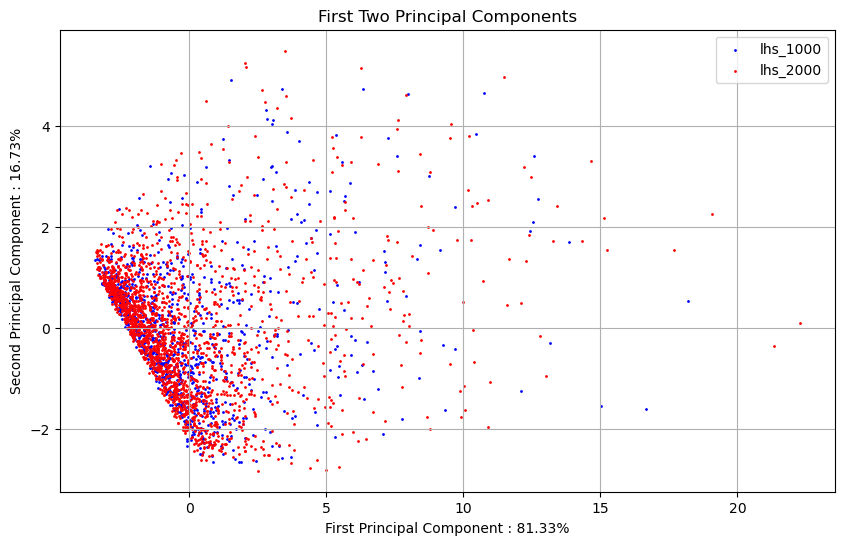

In [2]:
################################################################################
############ LHS1000/2000

l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000'
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]
l2000_files = []

l1000_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_1000/theory_2pcf'
l1000_files_names = sorted(glob.glob(f"{l1000_files_path}/id*2pcf.dat"))
l1000_files_full = [np.loadtxt(file) for file in l1000_files_names]
l1000_files = []

for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

for i in range(len(l1000_files_full)):
   data = l1000_files_full[i]
   row = [row[1] for row in data]
   l1000_files.append(row)

print("Shape max1000 : ",np.shape(l1000_files))
print("Shape max2000 : ",np.shape(l2000_files))

#####################################################################
full = np.concatenate([l1000_files,l2000_files])

# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(l1000_files) + [1]*len(l2000_files))
######################################################################

# Standardisation
scaler = StandardScaler()
scaled_full = scaler.fit_transform(full)

# PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_full)


# MASKS
# Create masks for the two groups
mask_l1000 = labels == 0
mask_l2000 = labels == 1

#Convexhull button
convexhull = 1

#Explained variance
fc1 = pca.explained_variance_ratio_[0]
fc2 = pca.explained_variance_ratio_[1]

# Plot the first two principal components
plt.figure(figsize=(10, 6))
plt.scatter(principal_components[mask_l1000, 0], principal_components[mask_l1000, 1],s=1,alpha=1,color='blue',label='lhs_1000')
plt.scatter(principal_components[mask_l2000, 0], principal_components[mask_l2000, 1],s=1,alpha=1,color='red',label='lhs_2000')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components')
plt.legend()
plt.grid()
plt.show()

Shape l_50_0 :  (100, 10)
Shape l_50_1 :  (100, 10)
Shape l_50_2 :  (100, 10)
Shape l_50_3 :  (100, 10)
Shape max1000 :  (2000, 10)


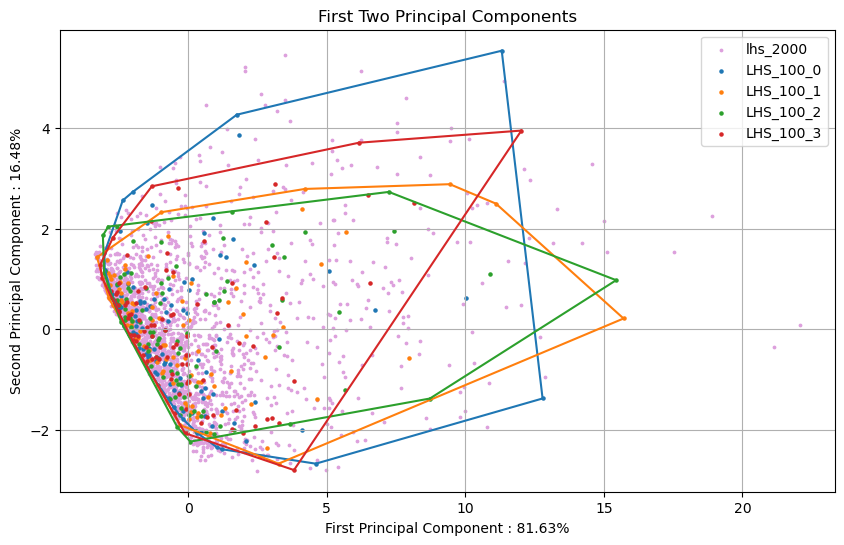

'count_green_positive_pc1 = np.sum(principal_components_maximin[mask_dbb1000, 0] > 10)\ncount_red_positive_pc1 = np.sum(principal_components_maximin[mask_max1000, 0] > 10)\nprint(f"Number of green points where the First Principal Component > 0: {count_green_positive_pc1}")\nprint(f"Number of red points where the First Principal Component > 0: {count_red_positive_pc1}")'

In [3]:
##################################################################################
######### LHS 100

seedlist=np.arange(4)
l100_files = []
for seed in seedlist:
    l100_files_path = f'/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_100_{seed}'
    l100_files_names = sorted(glob.glob(f"{l100_files_path}/id*2pcf.dat"))
    l100_files_full = [np.loadtxt(file) for file in l100_files_names]
    # Create list of measured files
    l100_0_files = []
    #for i in range(len(dbb1000_files_full)):
    for i in range(len(l100_files_full)):
        data = l100_files_full[i]
        row = [row[1] for row in data]
        l100_0_files.append(row)
    
    l100_files.append(l100_0_files)

    print(f"Shape l_100_{seed} : ",np.shape(l100_0_files))



l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000'
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]
l2000_files = []

for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape max1000 : ",np.shape(l2000_files))

#####################################################################
full = np.concatenate([l100_files[0],l100_files[1],l100_files[2],l100_files[3],l2000_files])

# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(l100_files[0]) + [1]*len(l100_files[1]) + [2]*len(l100_files[2]) + [3]*len(l100_files[3]) + [4]*len(l2000_files))
######################################################################

# Standardisation
scaler = StandardScaler()
scaled_full = scaler.fit_transform(full)

# PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_full)


# MASKS
# Create masks for the two groups
mask_l2000 = labels == 4

#COLORS
cmap = plt.get_cmap('tab10')
colors = [cmap(i) for i in range(len(seedlist))]

#Convexhull button
convexhull = 1

#Explained variance
fc1 = pca.explained_variance_ratio_[0]
fc2 = pca.explained_variance_ratio_[1]

# Plot the first two principal components
plt.figure(figsize=(10, 6))
plt.scatter(principal_components[mask_l2000, 0], principal_components[mask_l2000, 1],s=3,alpha=1,color='plum',label='lhs_2000')
for seed in seedlist : 
    mask_l100 = labels == seed
    plt.scatter(principal_components[mask_l100, 0], principal_components[mask_l100, 1],s=5,alpha=1,color=colors[seed],label=f'LHS_100_{seed}')

    if convexhull :
        l100_points = principal_components[mask_l100]
        hull_l100 = ConvexHull(l100_points)
        for simplex in hull_l100.simplices:
            plt.plot(l100_points[simplex, 0], l100_points[simplex, 1],color=colors[seed])

plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components')
plt.legend()
plt.grid()
plt.show()

"""count_green_positive_pc1 = np.sum(principal_components_maximin[mask_dbb1000, 0] > 10)
count_red_positive_pc1 = np.sum(principal_components_maximin[mask_max1000, 0] > 10)
print(f"Number of green points where the First Principal Component > 0: {count_green_positive_pc1}")
print(f"Number of red points where the First Principal Component > 0: {count_red_positive_pc1}")"""

Shape l_50_0 :  (50, 10)
Shape l_50_1 :  (50, 10)
Shape l_50_2 :  (50, 10)
Shape l_50_3 :  (50, 10)
Shape max1000 :  (2000, 10)


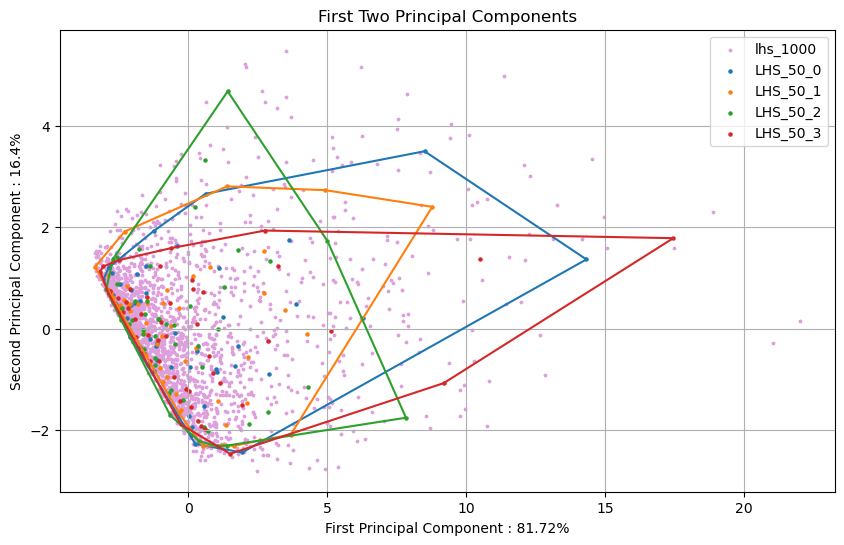

'count_green_positive_pc1 = np.sum(principal_components_maximin[mask_dbb1000, 0] > 10)\ncount_red_positive_pc1 = np.sum(principal_components_maximin[mask_max1000, 0] > 10)\nprint(f"Number of green points where the First Principal Component > 0: {count_green_positive_pc1}")\nprint(f"Number of red points where the First Principal Component > 0: {count_red_positive_pc1}")'

In [4]:
###################################################################################"
######### LHS 50

seedlist=np.arange(4)
l50_files = []
for seed in seedlist:
    l50_files_path = f'/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_50_{seed}'
    l50_files_names = sorted(glob.glob(f"{l50_files_path}/id*2pcf.dat"))
    l50_files_full = [np.loadtxt(file) for file in l50_files_names]
    # Create list of measured files
    l50_0_files = []
    #for i in range(len(dbb1000_files_full)):
    for i in range(len(l50_files_full)):
        data = l50_files_full[i]
        row = [row[1] for row in data]
        l50_0_files.append(row)
    
    l50_files.append(l50_0_files)

    print(f"Shape l_50_{seed} : ",np.shape(l50_0_files))



l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000'
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]
l2000_files = []

for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape max1000 : ",np.shape(l2000_files))

#####################################################################
full = np.concatenate([l50_files[0],l50_files[1],l50_files[2],l50_files[3],l2000_files])

# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(l50_files[0]) + [1]*len(l50_files[1]) + [2]*len(l50_files[2]) + [3]*len(l50_files[3]) + [4]*len(l2000_files))
######################################################################

# Standardisation
scaler = StandardScaler()
scaled_full = scaler.fit_transform(full)

# PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_full)


# MASKS
# Create masks for the two groups
mask_l2000 = labels == 4

#COLORS
cmap = plt.get_cmap('tab10')
colors = [cmap(i) for i in range(len(seedlist))]

#Convexhull button
convexhull = 1

#Explained variance
fc1 = pca.explained_variance_ratio_[0]
fc2 = pca.explained_variance_ratio_[1]

# Plot the first two principal components
plt.figure(figsize=(10, 6))
plt.scatter(principal_components[mask_l2000, 0], principal_components[mask_l2000, 1],s=3,alpha=1,color='plum',label='lhs_1000')
for seed in seedlist : 
    mask_l50 = labels == seed
    plt.scatter(principal_components[mask_l50, 0], principal_components[mask_l50, 1],s=5,alpha=1,color=colors[seed],label=f'LHS_50_{seed}')

    if convexhull :
        l50_points = principal_components[mask_l50]
        hull_l50 = ConvexHull(l50_points)
        for simplex in hull_l50.simplices:
            plt.plot(l50_points[simplex, 0], l50_points[simplex, 1],color=colors[seed])

plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components')
plt.legend()
plt.grid()
plt.show()

"""count_green_positive_pc1 = np.sum(principal_components_maximin[mask_dbb1000, 0] > 10)
count_red_positive_pc1 = np.sum(principal_components_maximin[mask_max1000, 0] > 10)
print(f"Number of green points where the First Principal Component > 0: {count_green_positive_pc1}")
print(f"Number of red points where the First Principal Component > 0: {count_red_positive_pc1}")"""

PLOT COLORMAPS

Shape l2000 :  (2000, 10)


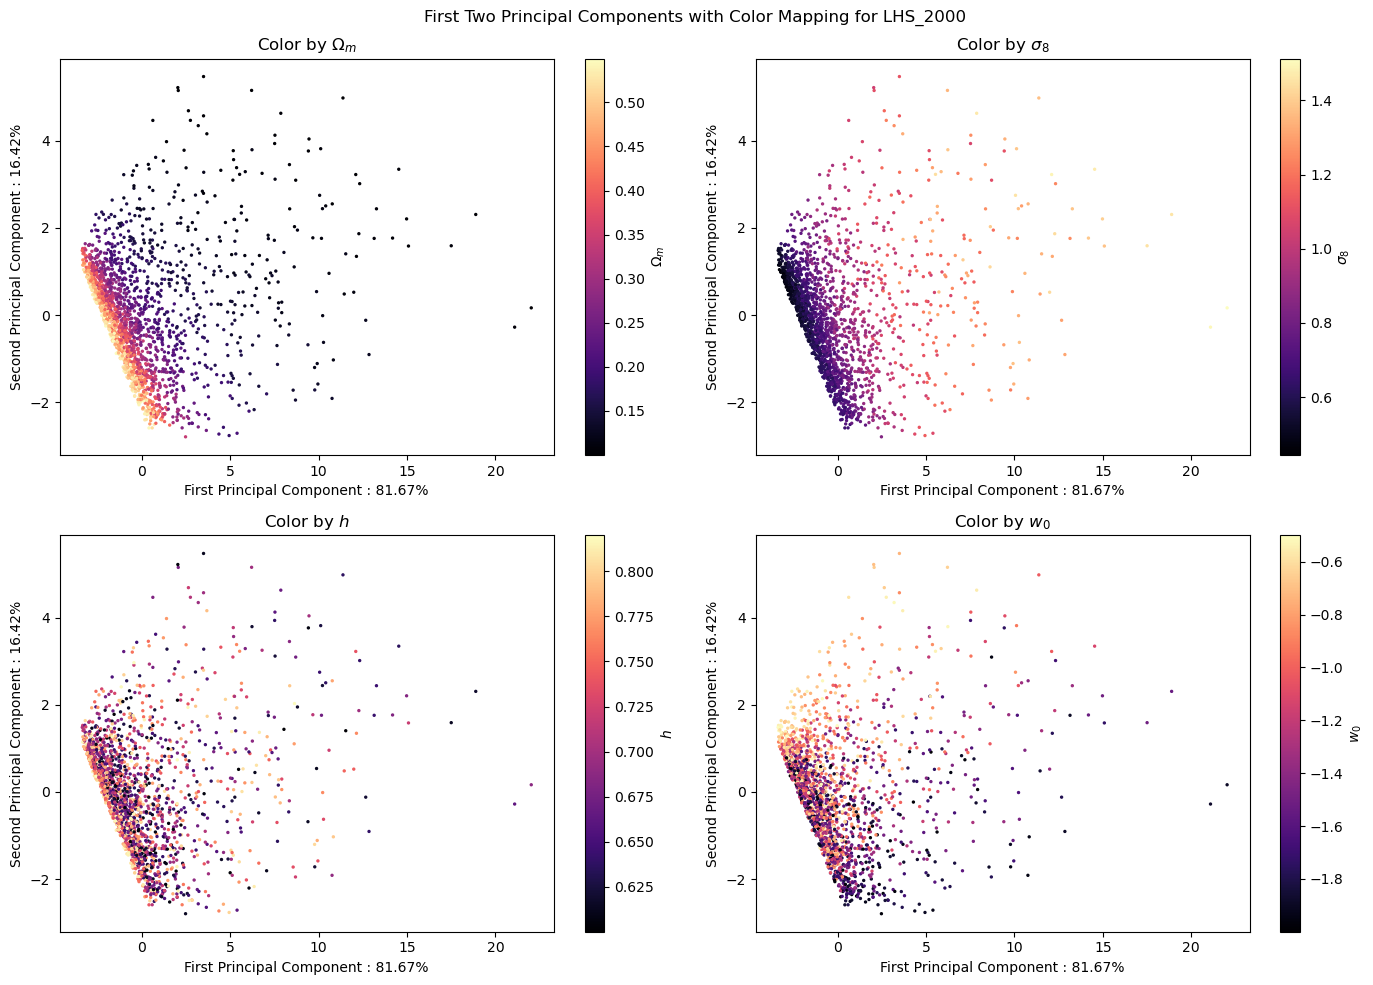

In [58]:
# Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$Final A_S$','$h$','$w_0$']
Om = params['Om']
sig8 = params['sig8']
h = params['h']
w0 = params['w0']
As = params['final_As']
params_values = [Om,As,h,w0]

l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape l2000 : ",np.shape(l2000_files))

########################################################################
# PCA
scaler = StandardScaler()
scaled = scaler.fit_transform(l2000_files)

pca = PCA(n_components=4)
principal_components = pca.fit_transform(scaled)

########################################################################
# Explained variance
explained_variance = pca.explained_variance_ratio_
fc1 = explained_variance[0]
fc2 = explained_variance[1]
plot_variance = 0

if plot_variance : 
# Plot explained variance ratio
   plt.figure(figsize=(10, 7))
   plt.bar(range(0, pca.n_components_), pca.explained_variance_ratio_, alpha=0.5, align='center')
   plt.plot(np.cumsum(explained_variance), marker='o')
   plt.ylabel('Variance proportion')
   plt.xlabel('Principal components')
   plt.title('Variance explained by each component')
   plt.grid()
   plt.show()
   print(pca.explained_variance_ratio_)


#####################################################################
# PLOTS

# Create subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plot each subplot
for i, ax in enumerate(axs.flat):
    scatter = ax.scatter(principal_components[:, 0], principal_components[:, 1], 
                         c=params_values[i], s=2, alpha=1, cmap='magma')
    ax.set_xlabel(f'First Principal Component : {round(100*fc1,2)}%')
    ax.set_ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
    ax.set_title(f'Color by {params_list[i]}')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label(params_list[i])
    #plt.vlines(x = x_max, ymin = -3 ,ymax = y_max, color = 'b')
    #plt.hlines(y = y_max, xmin = -5 ,xmax = x_max, color = 'b')

plt.suptitle('First Two Principal Components with Color Mapping for LHS_2000')
plt.tight_layout()
plt.show()

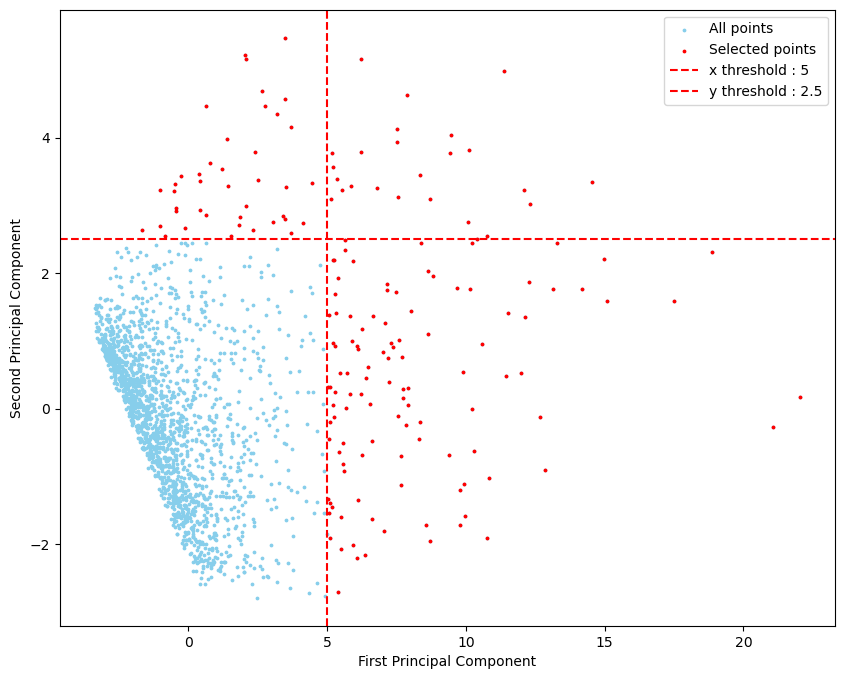

All points stats : 
                 Om           S8            h           w0         sig8
count  2000.000000  2000.000000  2000.000000  2000.000000  2000.000000
mean      0.325000     0.750000     0.710001    -1.249999     0.776586
std       0.129935     0.086623     0.063526     0.433114     0.210745
min       0.100175     0.600096     0.600069    -1.999922     0.444571
25%       0.212559     0.674998     0.654997    -1.624549     0.622348
50%       0.325005     0.749997     0.710008    -1.250348     0.728694
75%       0.437449     0.824895     0.764980    -0.875351     0.902020
max       0.549803     0.899921     0.819901    -0.500571     1.512783


Selected points stats : 
                Om          S8           h          w0        sig8
count  176.000000  176.000000  176.000000  176.000000  176.000000
mean     0.124836    0.777276    0.705550   -1.301500    1.211568
std      0.019197    0.086146    0.064248    0.444741    0.136346
min      0.100175    0.603421    0.600591   -1.9

In [60]:
x_max = 5
y_max = 2.5

# extract principal components
pc1 = principal_components[:, 0]
pc2 = principal_components[:, 1]

selected_indices = (pc1 >= x_max) | (pc2 >= y_max)
selected_params = params[selected_indices].iloc[:,:5]

plt.figure(figsize=(10, 8))
plt.scatter(pc1, pc2, color='skyblue', s = 3, label='All points')
plt.scatter(pc1[selected_indices], pc2[selected_indices], color='red', s = 3, label='Selected points')
plt.axvline(x=x_max, color='r', linestyle='--', label=f'x threshold : {x_max}')
plt.axhline(y=y_max, color='r', linestyle='--', label=f'y threshold : {y_max}')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.legend()
plt.show()

print("All points stats : \n",params.iloc[:,:5].describe())
print("\n")
print("Selected points stats : \n",selected_params.describe())

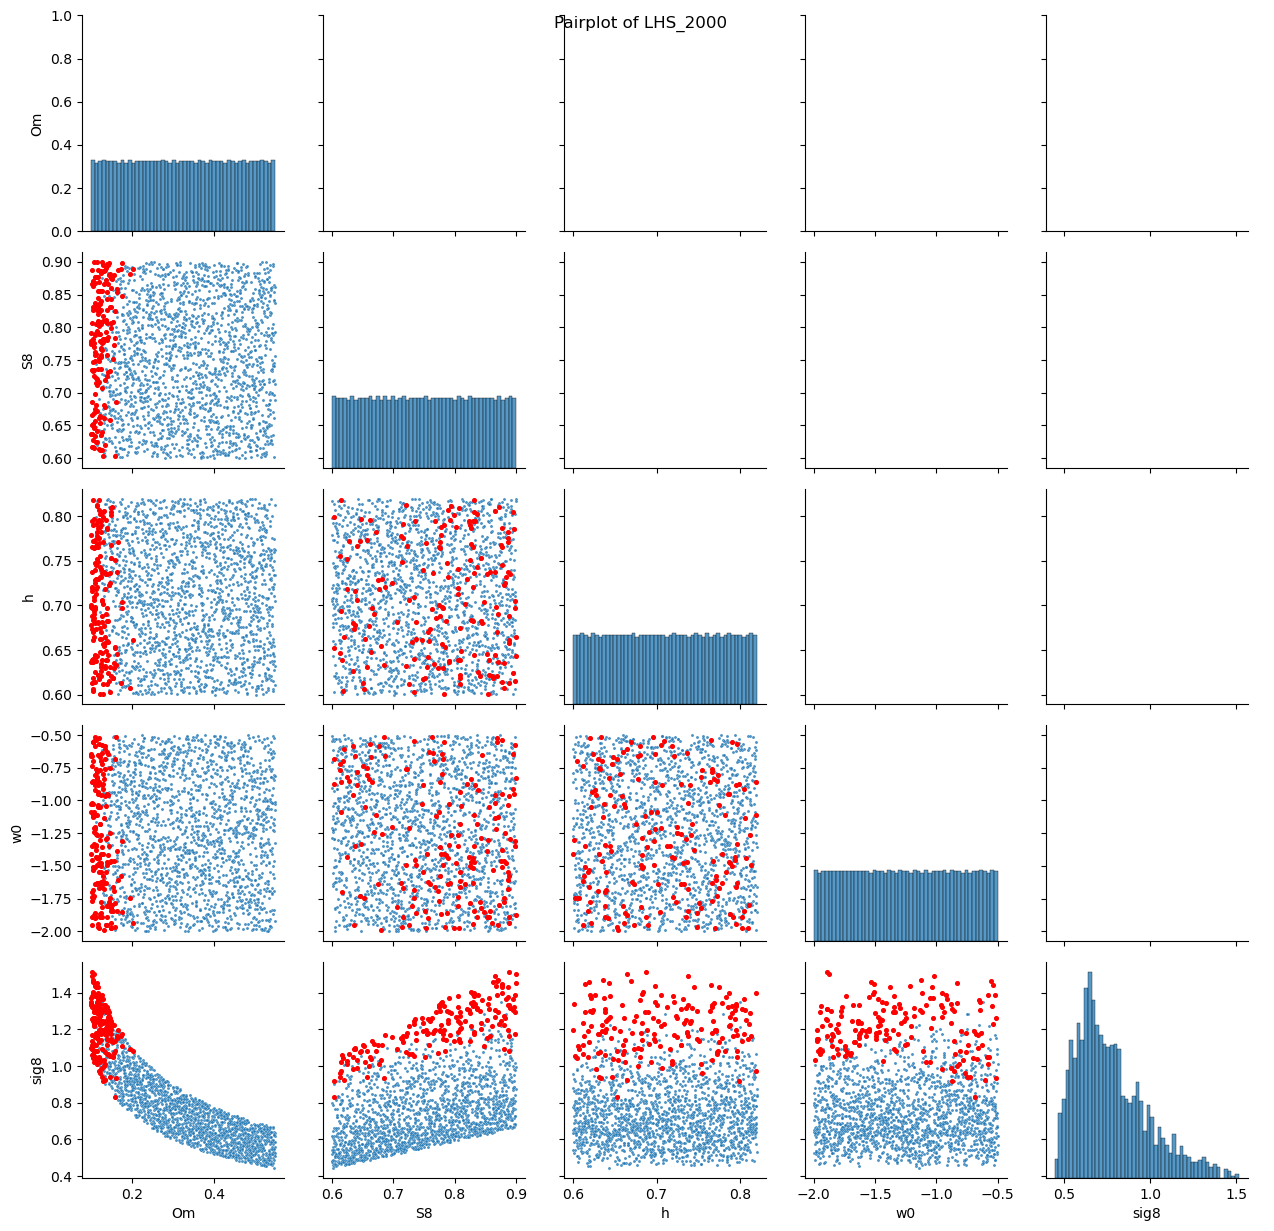

In [61]:
# PAIRPLOT
g = sns.PairGrid(params.iloc[:,:5])

g = g.map_lower(sns.scatterplot, s=5, alpha=0.8)  # Smaller points in the lower triangle

# SELECTED PARAMS PLOT
for i, j in zip(*np.tril_indices_from(g.axes, -1)):
    g.axes[i, j].scatter(selected_params.iloc[:, j], selected_params.iloc[:, i], color='red', s=7, alpha=1)


g = g.map_diag(sns.histplot, bins=50)  # Histogram on the diagonal

g.add_legend()

plt.suptitle('Pairplot of LHS_2000')
plt.show()

BUILD LHS FROM PCA

In [51]:
#Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$\sigma_8$','$h$','$w_0$']
Om = params['Om']
sig8 = params['sig8']
h = params['h']
w0 = params['w0']
params_values = [Om,sig8,h,w0]

l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape l2000 : ",np.shape(l2000_files))

########################################################################
# PCA
scaler = StandardScaler()
scaled = scaler.fit_transform(l2000_files)

pca = PCA(n_components=4)
principal_components = pca.fit_transform(scaled)

pc1 = principal_components[:, 0]
pc2 = principal_components[:, 1]

Shape l2000 :  (2000, 10)


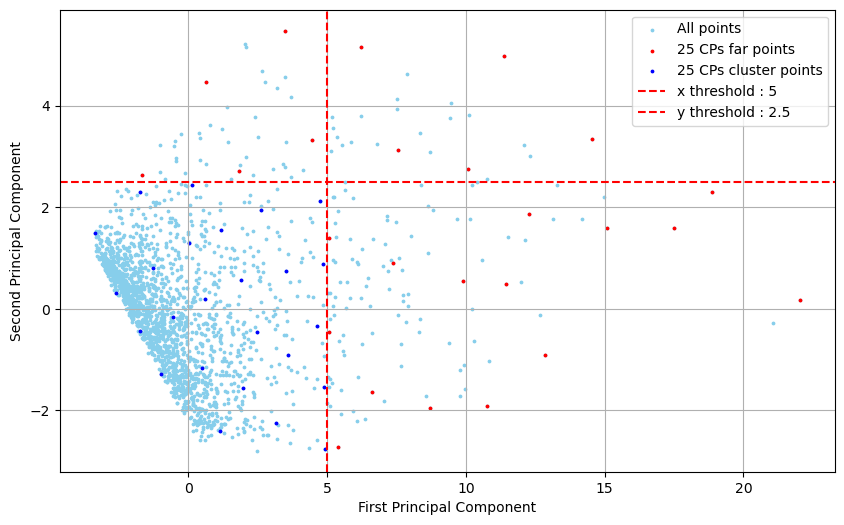

In [55]:
xmax = 5
ymax = 2.5
selected_indices = (pc1 >= xmax) | (pc2 >= ymax)
selected_indices

x_far = pc1[selected_indices]
y_far = pc2[selected_indices]
points_far = list(zip(x_far,y_far))

x_cl = pc1[~selected_indices]
y_cl = pc2[~selected_indices]
points_cl = list(zip(x_cl,y_cl))

def maximin_distance(points, num_points_to_select):
    selected_points = []
    selected_points.append(points[0])  # Take first point (arbitrary)
    
    while len(selected_points) < num_points_to_select:
        max_min_distance = -1
        next_point = None
        
        for point in points:
            if point not in selected_points:
                min_distance = math.inf
                
                for selected_point in selected_points:
                    distance = math.sqrt((point[0] - selected_point[0])**2 + (point[1] - selected_point[1])**2)
                    if distance < min_distance:
                        min_distance = distance
                
                if min_distance > max_min_distance:
                    max_min_distance = min_distance
                    next_point = point
        
        selected_points.append(next_point)
    
    np.array(selected_points)

    selected_indices = []
    for point in selected_points:
        index = np.where((pc1 == point[0]) & (pc2 == point[1]))[0][0]
        selected_indices.append(index)
        
    return selected_indices

selected_indices_far = maximin_distance(points_far, 25)
selected_indices_cl = maximin_distance(points_cl, 25)

plt.figure(figsize=(10, 6))
plt.scatter(pc1, pc2, color='skyblue', s=3, label='All points')
plt.scatter(pc1[selected_indices_far],pc2[selected_indices_far] , color='red', s=3, label='25 CPs far points')
plt.scatter(pc1[selected_indices_cl],pc2[selected_indices_cl] , color='blue', s=3, label='25 CPs cluster points')
plt.axvline(x=xmax, color='r', linestyle='--', label=f'x threshold : {xmax}')
plt.axhline(y=ymax, color='r', linestyle='--', label=f'y threshold : {ymax}')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.grid()
plt.legend()
plt.show()

far_lhs = params.iloc[selected_indices_far, :]
cl_lhs = params.iloc[selected_indices_cl, :]

# Afficher les statistiques descriptives
#print("Selected points stats (Red points) : \n", red_lhs)
#print('\n')
#print("Selected points stats (Blue points) : \n", blue_lhs.describe())

#red_lhs = red_lhs.reset_index(drop=True)
far_lhs.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/pca_lhs/far_lhs_25.csv')
cl_lhs.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/pca_lhs/cluster_lhs_25.csv')

Shape 25 :  (25, 10)
Shape max2000 :  (2000, 10)


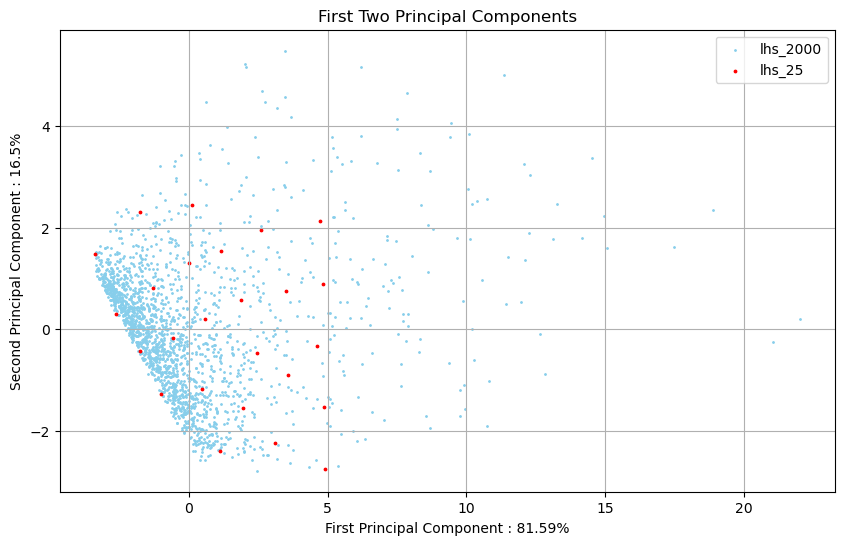

,Om,S8,h,w0,sig8
0,0.204953,0.881410,0.644790,-0.851002,1.066379
1,0.400557,0.600663,0.707015,-0.507690,0.519828
2,0.132665,0.676331,0.767388,-0.817038,1.017050
3,0.539465,0.859280,0.819253,-0.552541,0.640787
4,0.113161,0.743349,0.799302,-1.165792,1.210331
5,0.182404,0.893580,0.800906,-1.903629,1.145979
6,0.448601,0.890156,0.614027,-1.619795,0.727941
7,0.170154,0.875888,0.635096,-1.048276,1.163021
8,0.114291,0.620062,0.817642,-1.649818,1.004593
9,0.278214,0.732634,0.617492,-0.648300,0.760779


In [63]:
################################################################################
############ LHS1000/2000
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]
l2000_files = []

l25_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/pca_lhs/cluster_lhs_25'
l25_files_names = sorted(glob.glob(f"{l25_files_path}/id*2pcf.dat"))
l25_files_full = [np.loadtxt(file) for file in l25_files_names]
l25_files = []

params = pd.read_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/pca_lhs/cluster_lhs_25.csv')

for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

for i in range(len(l25_files_full)):
   data = l25_files_full[i]
   row = [row[1] for row in data]
   l25_files.append(row)

print("Shape 25 : ",np.shape(l25_files))
print("Shape max2000 : ",np.shape(l2000_files))

#####################################################################
full = np.concatenate([l25_files,l2000_files])

# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(l25_files) + [1]*len(l2000_files))
######################################################################

# Standardisation
scaler = StandardScaler()
scaled_full = scaler.fit_transform(full)

# PCA
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_full)


# MASKS
# Create masks for the two groups
mask_l25 = labels == 0
mask_l2000 = labels == 1

#Convexhull button
convexhull = 1

#Explained variance
fc1 = pca.explained_variance_ratio_[0]
fc2 = pca.explained_variance_ratio_[1]

# Plot the first two principal components
plt.figure(figsize=(10, 6))
plt.scatter(principal_components[mask_l2000, 0], principal_components[mask_l2000, 1],s=1,alpha=1,color='skyblue',label='lhs_2000')
plt.scatter(principal_components[mask_l25, 0], principal_components[mask_l25, 1],s=3,alpha=1,color='red',label='lhs_25')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.title('First Two Principal Components')
plt.legend()
plt.grid()
plt.show()

params.iloc[:,1:6]

CAMB CRASHES

Shape l2000 :  (2000, 10)


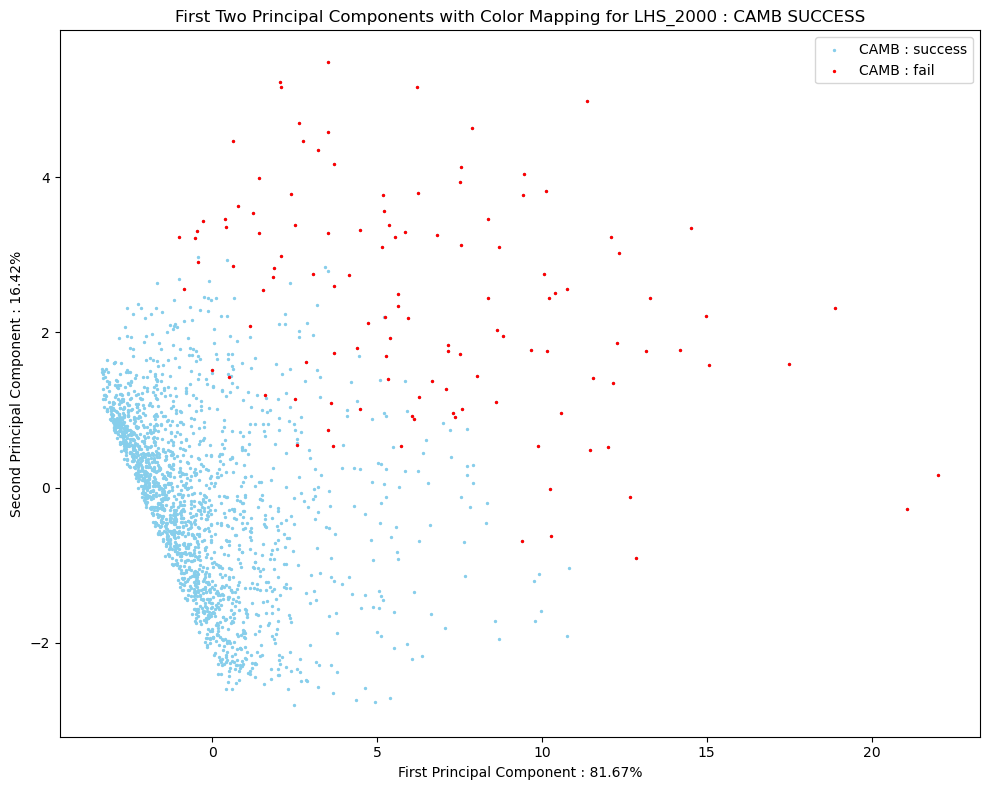

In [3]:
# Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$S_8$','$h$','$w_0$']
camb_res = params['camb_res']
params_crash = params[params['camb_res']==0]

l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape l2000 : ",np.shape(l2000_files))

########################################################################
# PCA
scaler = StandardScaler()
scaled = scaler.fit_transform(l2000_files)

pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled)
pc1 = principal_components[:, 0]
pc2 = principal_components[:, 1]

########################################################################
# Explained variance
explained_variance = pca.explained_variance_ratio_
fc1 = explained_variance[0]
fc2 = explained_variance[1]
plot_variance = 0

if plot_variance : 
# Plot explained variance ratio
   plt.figure(figsize=(10, 7))
   plt.bar(range(0, pca.n_components_), pca.explained_variance_ratio_, alpha=0.5, align='center')
   plt.plot(np.cumsum(explained_variance), marker='o')
   plt.ylabel('Variance proportion')
   plt.xlabel('Principal components')
   plt.title('Variance explained by each component')
   plt.grid()
   plt.show()
   print(pca.explained_variance_ratio_)


#####################################################################
# PLOTS


# Create subplots
fig= plt.figure(figsize=(10, 8))

plt.scatter(principal_components[:, 0], principal_components[:, 1], s=2, alpha=1,color='skyblue', label='CAMB : success')
plt.scatter(principal_components[params_crash.iloc[:,0], 0], principal_components[params_crash.iloc[:,0], 1], s=2, alpha=1,color='red', label='CAMB : fail')
#plt.scatter(principal_components[1008, 0], principal_components[1008, 1], s=20, alpha=1,color='orange', label='CAMB : success')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.legend()
plt.title('First Two Principal Components with Color Mapping for LHS_2000 : CAMB SUCCESS')
plt.tight_layout()
plt.show()

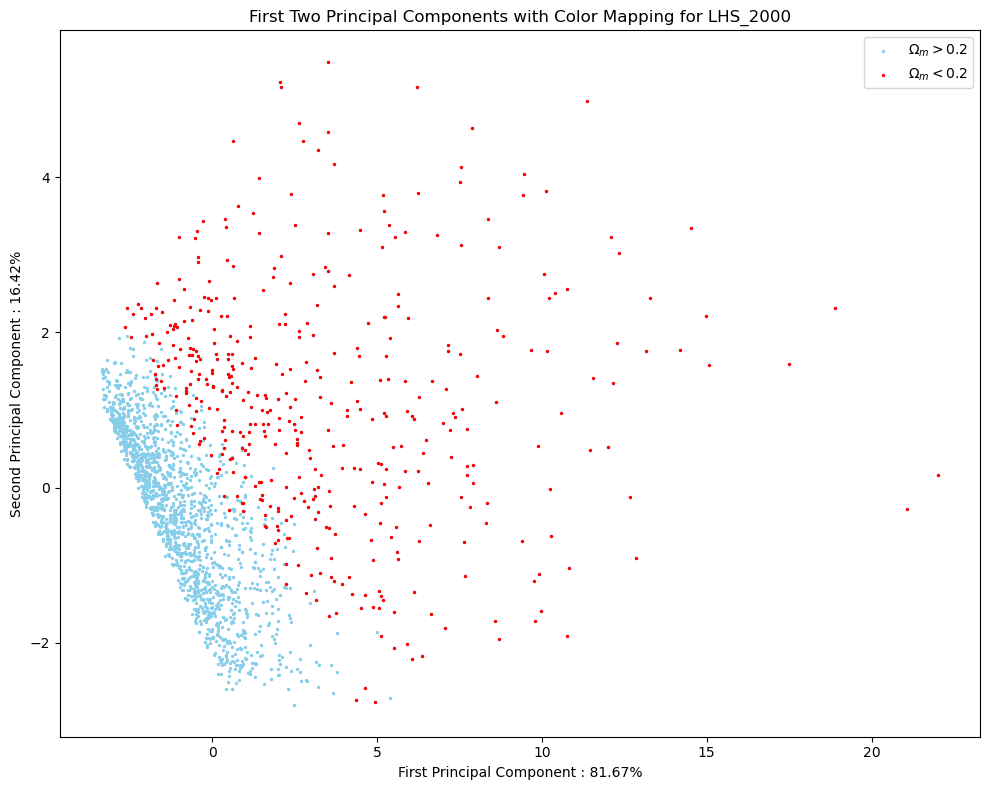

In [14]:
data = params[params['Om']<=0.2]
fig= plt.figure(figsize=(10, 8))
plt.scatter(principal_components[:, 0], principal_components[:, 1], s=2, alpha=1,color='skyblue', label='$\Omega_m > 0.2$')
plt.scatter(principal_components[np.array(data['Unnamed: 0']), 0], principal_components[np.array(data['Unnamed: 0']), 1], s=2, alpha=1,color='red', label='$\Omega_m < 0.2$')
#plt.scatter(principal_components[1008, 0], principal_components[1008, 1], s=20, alpha=1,color='orange', label='CAMB : success')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.legend()
plt.title('First Two Principal Components with Color Mapping for LHS_2000')
plt.tight_layout()
plt.show()

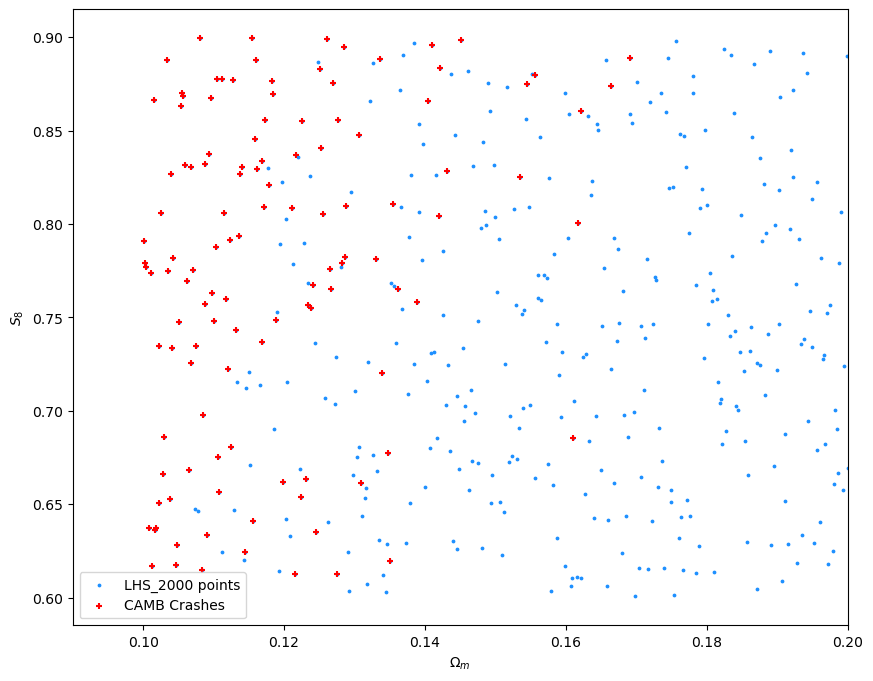

In [16]:
camb_crash_indices = np.array(params_crash.iloc[:,0])
Om = params['Om']
S8 = params['S8']

plt.figure(figsize=(10,8))
plt.scatter(Om,S8, s=3, color='dodgerblue', label='LHS_2000 points')
plt.scatter(Om[camb_crash_indices],S8[camb_crash_indices], s=20, color='red', label='CAMB Crashes', marker ='+')
plt.xlabel('$\Omega_m$')
plt.ylabel('$S_8$')
plt.legend()
plt.xlim(0.09,0.2)
plt.show()

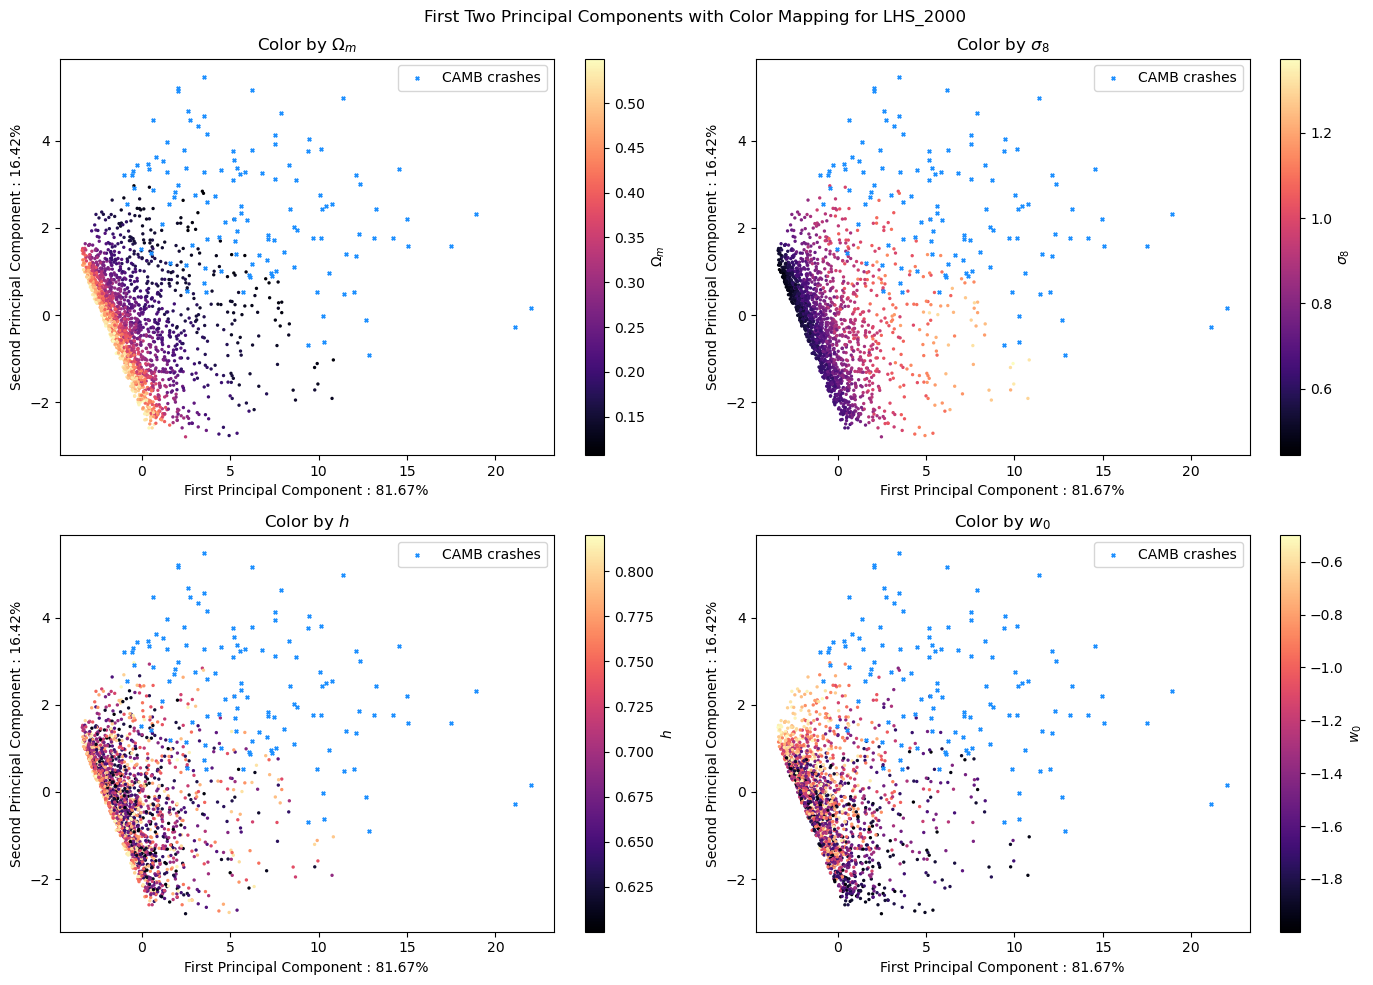

In [3]:
# Path to files
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$\sigma_8$','$h$','$w_0$']
Om = params['Om']
S8 = params['S8']
sig8 = params['sig8']
h = params['h']
w0 = params['w0']
params_values = [Om,sig8,h,w0]

#####################################################################
# PLOTS

# Create subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plot each subplot
for i, ax in enumerate(axs.flat):
    # Create a mask for indices that are not in params_crash
    mask = np.ones(len(principal_components), dtype=bool)
    mask[params_crash.iloc[:,0]] = False
    
    # Scatter plot for all points except those in params_crash
    scatter = ax.scatter(principal_components[mask, 0], principal_components[mask, 1], 
                         c=np.array(params_values[i])[mask], s=2, alpha=1, cmap='magma')
    scatter1 = ax.scatter(principal_components[params_crash.iloc[:,0], 0], principal_components[params_crash.iloc[:,0], 1], 
                         marker="x",s=6, alpha=1, color='dodgerblue', label='CAMB crashes')
    ax.legend()
    ax.set_xlabel(f'First Principal Component : {round(100*fc1,2)}%')
    ax.set_ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
    ax.set_title(f'Color by {params_list[i]}')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label(params_list[i])
    #plt.vlines(x = x_max, ymin = -3 ,ymax = y_max, color = 'b')
    #plt.hlines(y = y_max, xmin = -5 ,xmax = x_max, color = 'b')

plt.suptitle('First Two Principal Components with Color Mapping for LHS_2000')
plt.tight_layout()
plt.show()

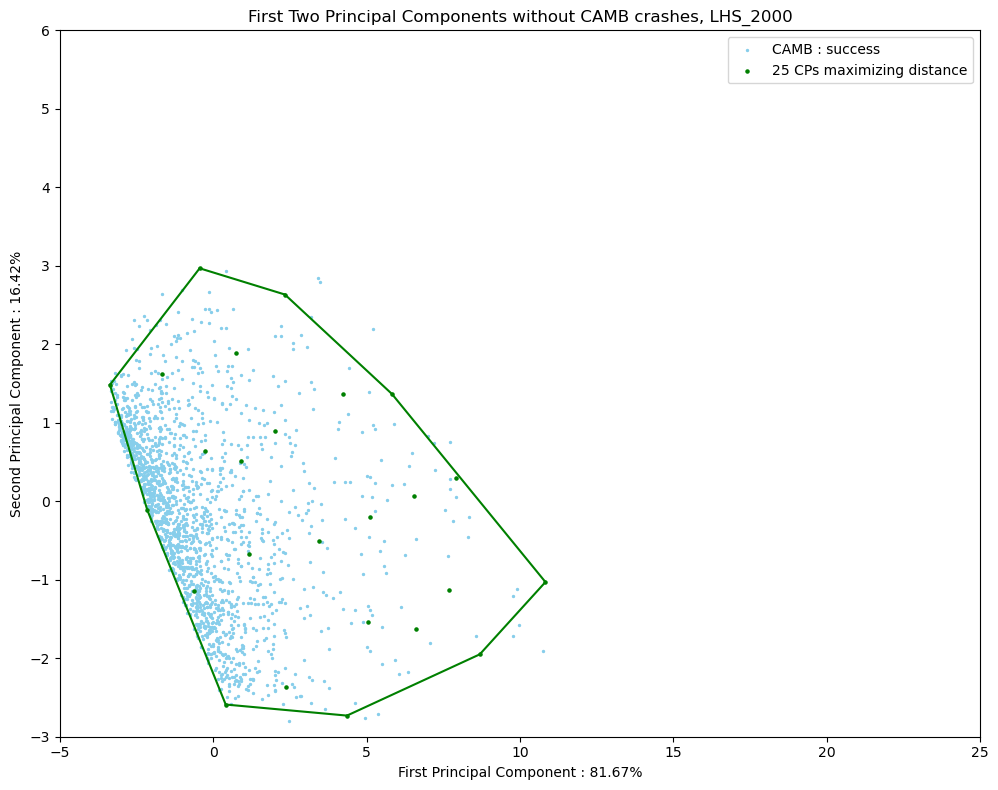

In [5]:
def maximin_distance(points, n_points,pc1,pc2):
    selected_points = []
    selected_points.append(points[0])  # Take first point (arbitrary)
    
    while len(selected_points) < n_points:
        max_min_distance = -1
        next_point = None
        
        for point in points:
            if point not in selected_points:
                min_distance = math.inf
                
                for selected_point in selected_points:
                    distance = math.sqrt((point[0] - selected_point[0])**2 + (point[1] - selected_point[1])**2)
                    if distance < min_distance:
                        min_distance = distance
                
                if min_distance > max_min_distance:
                    max_min_distance = min_distance
                    next_point = point
        
        selected_points.append(next_point)
    
    np.array(selected_points)
    
    selected_indices = []
    for point in selected_points:
        index = np.where((pc1 == point[0]) & (pc2 == point[1]))[0][0]
        selected_indices.append(index)
        
    return selected_indices


indices_to_exclude = params_crash.iloc[:, 0].values
mask = np.ones(principal_components.shape[0], dtype=bool)
mask[indices_to_exclude] = False

pc1_without_camb = pc1[mask]
pc2_without_camb = pc2[mask]

points = list(zip(pc1_without_camb,pc2_without_camb))

selected_indices = maximin_distance(points, 25,pc1,pc2)


fig= plt.figure(figsize=(10, 8))
scatter = plt.scatter(pc1_without_camb,pc2_without_camb, s=2, alpha=1,color='skyblue', label='CAMB : success')
plt.scatter(pc1[selected_indices],pc2[selected_indices],color='green', s=5, label='25 CPs maximizing distance')
#plt.scatter(principal_components[params_crash.iloc[:,0], 0], principal_components[params_crash.iloc[:,0], 1], s=2, alpha=1,color='red', label='CAMB : fail')
convexhull=1
if convexhull :
    # Calculate and plot the convex hull for the blue points
    cosmo_points = principal_components[selected_indices]
    hull = ConvexHull(cosmo_points)
    for simplex in hull.simplices:
        plt.plot(cosmo_points[simplex, 0], cosmo_points[simplex, 1], color='green')
        
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.legend()
plt.title('First Two Principal Components without CAMB crashes, LHS_2000')
plt.tight_layout()
plt.xlim(-5,25)
plt.ylim(-3,6)
plt.show()

camb_lhs = params.iloc[selected_indices, :]

camb_lhs.to_csv('/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/pca_lhs/camb_lhs_25.csv')

/tmp/ipykernel_69543/617126797.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


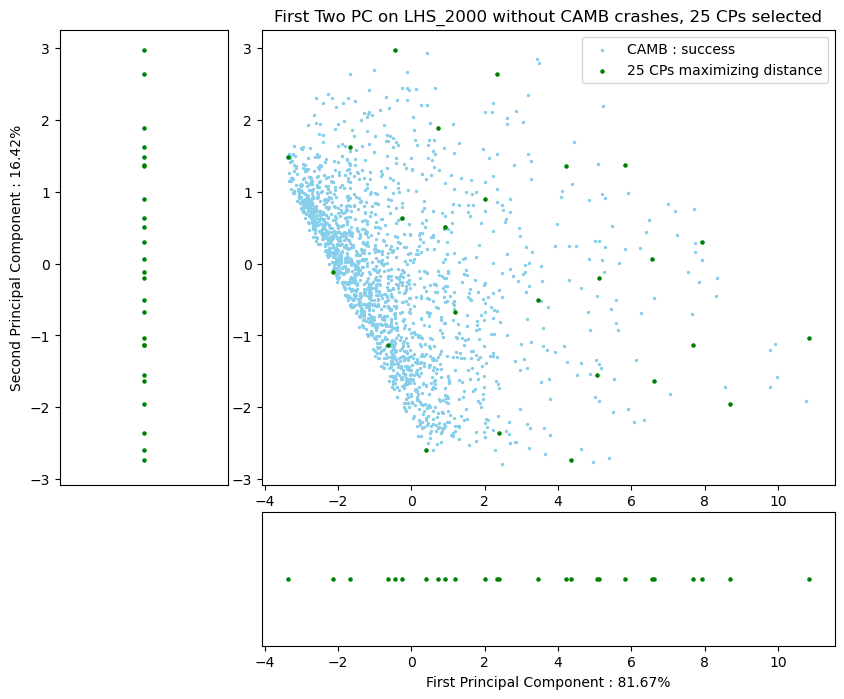

In [14]:
fig = plt.figure(figsize=(10, 8))

# Subplots dimensions
grid = plt.GridSpec(4, 4, hspace=0.2, wspace=0.2)

# Main plot
main_ax = fig.add_subplot(grid[:-1, 1:])

# Axes projection
y_hist = fig.add_subplot(grid[:-1, 0], xticklabels=[], sharey=main_ax)
x_hist = fig.add_subplot(grid[-1, 1:], yticklabels=[], sharex=main_ax)

# Scatter main plot
scatter = main_ax.scatter(pc1_without_camb, pc2_without_camb, s=2, alpha=1, color='skyblue', label='CAMB : success')
main_ax.scatter(pc1[selected_indices], pc2[selected_indices], color='green', s=5, label='25 CPs maximizing distance')

# compute and plot convex hull
convexhull = 0
if convexhull:
    cosmo_points = principal_components[selected_indices]
    hull = ConvexHull(cosmo_points)
    for simplex in hull.simplices:
        main_ax.plot(cosmo_points[simplex, 0], cosmo_points[simplex, 1], color='green')

x_hist.scatter(pc1[selected_indices], [0] * len(pc1[selected_indices]), color='green', s=5)
y_hist.scatter([0] * len(pc2[selected_indices]), pc2[selected_indices], color='green', s=5)

# width and all
main_ax.set_xlabel(f'First Principal Component : {round(100 * fc1, 2)}%')
main_ax.set_ylabel(f'Second Principal Component : {round(100 * fc2, 2)}%')
x_hist.set_xlim(main_ax.get_xlim())
y_hist.set_ylim(main_ax.get_ylim())
x_hist.xaxis.set_label_position('bottom')
x_hist.set_xlabel(f'First Principal Component : {round(100 * fc1, 2)}%')

y_hist.yaxis.set_label_position('left')
y_hist.set_ylabel(f'Second Principal Component : {round(100 * fc2, 2)}%')

main_ax.legend()
main_ax.set_title('First Two PC on LHS_2000 without CAMB crashes, 25 CPs selected')

# masks
x_hist.yaxis.set_major_locator(plt.NullLocator())
y_hist.xaxis.set_major_locator(plt.NullLocator())

plt.tight_layout()
plt.show()

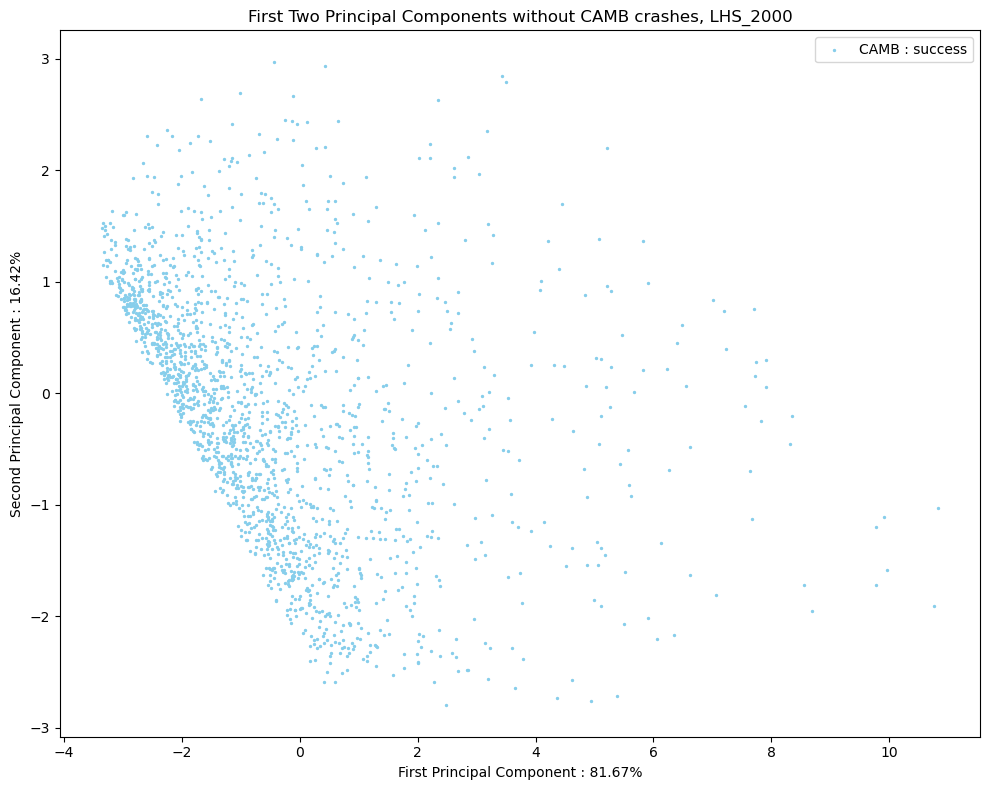

In [37]:
def min_max(x, inf=1e-10, sup=1):
        mini = np.min(x)
        maxi = np.max(x)
        return (sup - inf) * (x - mini) / (maxi - mini) + inf

pc1_norm = min_max(pc1_without_camb,np.min(pc1_without_camb),np.max(pc1_without_camb))
pc2_norm = min_max(pc2_without_camb,np.min(pc2_without_camb),np.max(pc2_without_camb))

fig= plt.figure(figsize=(10, 8))
plt.scatter(pc1_norm,pc2_norm, s=2, alpha=1,color='skyblue', label='CAMB : success')
plt.xlabel(f'First Principal Component : {round(100*fc1,2)}%')
plt.ylabel(f'Second Principal Component : {round(100*fc2,2)}%')
plt.legend()
plt.title('First Two Principal Components without CAMB crashes, LHS_2000')
plt.tight_layout()
plt.show()

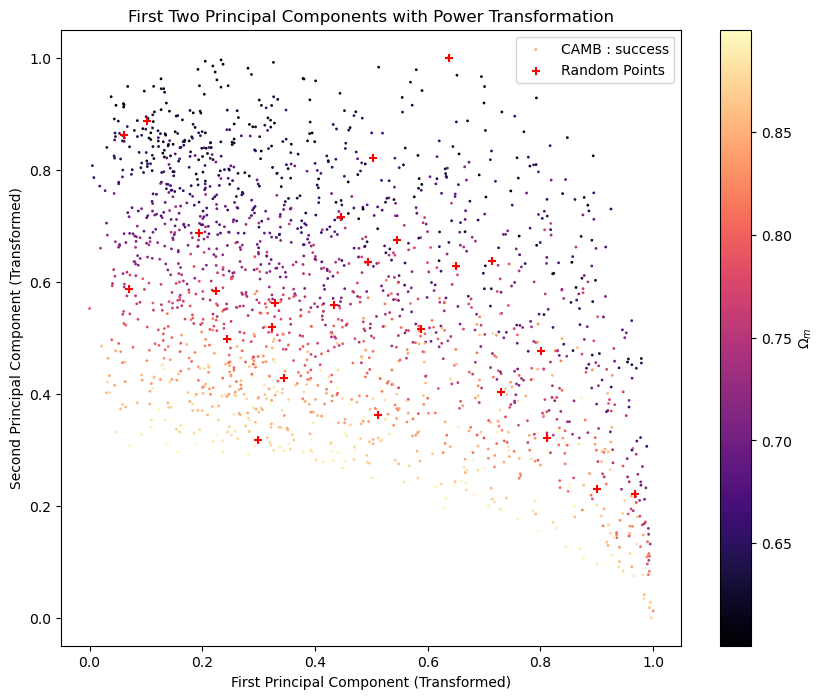

In [72]:
from matplotlib.transforms import Affine2D
from pyDOE import lhs

def rotate_points(x, y, angle_degrees):
    angle_rad = np.deg2rad(angle_degrees)
    rotation_matrix = np.array([[np.cos(angle_rad), -np.sin(angle_rad)],
                                [np.sin(angle_rad), np.cos(angle_rad)]])
    rotated_points = np.dot(rotation_matrix, np.vstack([x, y]))
    return rotated_points[0], rotated_points[1]

rotated_pc1, rotated_pc2 = rotate_points(pc1_without_camb, pc2_without_camb, -45)
pc1_norm = min_max(rotated_pc1)
pc2_norm = min_max(rotated_pc2)

points_test = list(zip(pc1_norm,pc2_norm))

pt = PowerTransformer(method='yeo-johnson')

data_transformed = pt.fit_transform(np.column_stack((pc1_norm, pc2_norm)))

x_transformed = data_transformed[:, 0]
y_transformed = data_transformed[:, 1]

x_norm = min_max(x_transformed)
y_norm = min_max(y_transformed)

# TAKE RANDOM POINTS
np.random.seed(2)
indices_rand = np.random.choice(len(x_norm),size=25,replace=False)
x_rand = x_norm[indices_rand]
y_rand = y_norm[indices_rand]

# plot transformed data
plt.figure(figsize=(10, 8))
scatter = plt.scatter(x_norm, y_norm, c=S8.iloc[mask], s=1, label='CAMB : success', cmap='magma')
scatter1 = plt.scatter(x_rand, y_rand,s=30,color='red',marker='+',label='Random Points')
plt.xlabel('First Principal Component (Transformed)')
plt.ylabel('Second Principal Component (Transformed)')
plt.title('First Two Principal Components with Power Transformation')
plt.legend()
cbar = plt.colorbar(scatter)
cbar.set_label(params_list[0])
plt.show()